# Quantum annealing evolution: bath relaxation and local SEAQT

An open-system model for quantum annealing: a qubit register coupled to a
fixed-temperature bath, driven by the real D-Wave QPU annealing
Hamiltonian. This notebook walks through the physics, validates it live,
and builds up from 1 qubit to 2 coupled qubits, using **two** dissipators:

1. **`bath_dissipator`** (sections 1-3, 6) -- the whole composite system
   relaxes toward a single global Gibbs state.
2. **`local_seaqt_dissipator`** (sections 5, 7) -- from Yamada, Kusaba,
   Li, von Spakovsky et al., arXiv:2404.05473v3 (eqs. 6, 7, 15); each
   qubit relaxes *locally*, coupled to the other only through their
   current reduced states.

**Physics common to both**

$$\dot\rho\big|_{\text{unitary}} = -\frac{i}{\hbar}[H(t), \rho]$$

with the D-Wave QPU Hamiltonian

$$H(s) = -\frac{A(s)}{2}\sum_i \sigma_x^{(i)} + \frac{B(s)}{2}\Big(\sum_i h_i \sigma_z^{(i)} + \sum_{i<j} J_{ij}\sigma_z^{(i)}\sigma_z^{(j)}\Big)$$

$A(s), B(s)$ read from the real QPU datasheet, $s=t/t_{\text{anneal}}\in[0,1]$.

**`bath_dissipator`** relaxes $\rho$ toward the Gibbs (canonical) state
$e^{-\beta H}/Z$ at bath inverse temperature $\beta$:

$$\dot\rho\big|_{\text{diss}} = -\frac{\beta}{2\tau}\{F(\rho,H,\beta),\rho\},
  \qquad F = (H-\langle H\rangle_\rho I) - \tfrac{1}{\beta}(S_{\mathrm{op}}-\langle S_{\mathrm{op}}\rangle_\rho I)$$

with $S_{\mathrm{op}}=-\ln\rho$. Both bracketed terms are "fluctuation
operators" with zero expectation in $\rho$ by construction, which is what
guarantees trace conservation with no extra projection step. Its 2nd-law
equivalent: the free energy $\Omega(\rho)=\langle H\rangle_\rho - S(\rho)/\beta$
decreases monotonically to its minimum at the Gibbs state.

**`local_seaqt_dissipator`** relaxes each qubit $J\in\{A,B\}$ locally:

$$\dot\rho\big|_{\text{diss}} = -\tfrac{1}{\tau_A} D_A\otimes\rho_B - \tfrac{1}{\tau_B}\rho_A\otimes D_B,
  \qquad D_J = \rho_J\ln\rho_J - \beta_R\langle f\rangle_J\rho_J + \tfrac{1}{2}\beta_R\{H_J,\rho_J\}$$

with $\rho_A=\mathrm{Tr}_B(\rho)$, $H_J$ the "locally perceived" Hamiltonian
(traced over the other qubit, weighted by its current state). `Tr(D_J)=0`
exactly by construction (see section 7), but **positivity of $\rho$ is not
guaranteed** for this one -- see section 7.

See `README.md` for the full derivation and sign/unit conventions.

In [3]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from seaqt import bath_dissipator, entropy, evolve, free_energy, free_energy_operator, gibbs_state, hermitize, population_distribution
from seaqt.local_seaqt import local_seaqt_dissipator, locally_perceived_operator, reduced_state, _subsystem_dissipator
from seaqt.operators import basis_labels, ising_hamiltonian, sigma_x, sigma_z
from seaqt.dwave import load_schedule, hamiltonian_1qubit, hamiltonian_nqubit, beta_from_kelvin

SCHEDULE_PATH = (
    r"C:\Users\andre\OneDrive\Documentos\Maestría\Julich\codigos"
    r"\09-1265A-C_Advantage_system5_3_annealing_schedule.xlsx"
)

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(precision=4, suppress=True)
print("Setup OK.")

Setup OK.


## 1. Physics validation, live

Rather than just trusting the tests, compute the dissipator directly and
check the invariants it claims to satisfy: trace conservation, and that it
vanishes exactly at the Gibbs equilibrium state.

In [4]:
H_demo = 0.5 * sigma_z + 0.3 * sigma_x
beta_demo = 1.5

rho_eq = gibbs_state(H_demo, beta_demo)
D_at_eq = bath_dissipator(rho_eq, H_demo, beta_demo, tau=1.0)
print("Dissipator at the Gibbs state (should be ~0):")
print(D_at_eq)
print(f"max|D| = {np.max(np.abs(D_at_eq)):.3e}")

rho_away = np.array([[0.6, 0.15 - 0.1j], [0.15 + 0.1j, 0.4]], dtype=complex)
D_away = bath_dissipator(rho_away, H_demo, beta_demo, tau=1.0)
print(f"\nAway from equilibrium, max|D| = {np.max(np.abs(D_away)):.3e} (nonzero, as expected)")
print(f"Tr(D)   = {np.trace(D_away):.3e}  (want 0)")

Dissipator at the Gibbs state (should be ~0):
[[-0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j]]
max|D| = 1.938e-16

Away from equilibrium, max|D| = 4.348e-01 (nonzero, as expected)
Tr(D)   = 0.000e+00+0.000e+00j  (want 0)


## 2. One qubit -- real D-Wave schedule + bath relaxation

A simpler stepping stone before 2 qubits: single qubit, real QPU schedule,
relaxing toward a fixed-temperature bath. Note D-Wave's sign convention:
no leading minus on the $B(s)$ term, so the ground state is $|0\rangle$
for $h_1<0$.

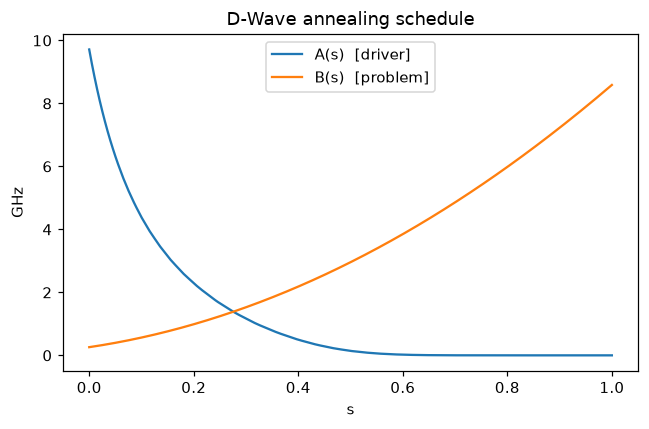

In [5]:
schedule = load_schedule(SCHEDULE_PATH)
s_grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(s_grid, schedule.A(s_grid), label="A(s)  [driver]")
ax.plot(s_grid, schedule.B(s_grid), label="B(s)  [problem]")
ax.set_xlabel("s"); ax.set_ylabel("GHz"); ax.legend(); ax.set_title("D-Wave annealing schedule")
fig.tight_layout(); plt.show()

beta (15 mK) = 0.5092 ns
             tau=2: final P(|0>)=0.0239, final entropy=0.1127, final Omega=-4.3096
            tau=10: final P(|0>)=0.0048, final entropy=0.0302, final Omega=-4.3115
 tau=inf (unitary): final P(|0>)=0.0003, final entropy=0.0000, final Omega=-4.2909


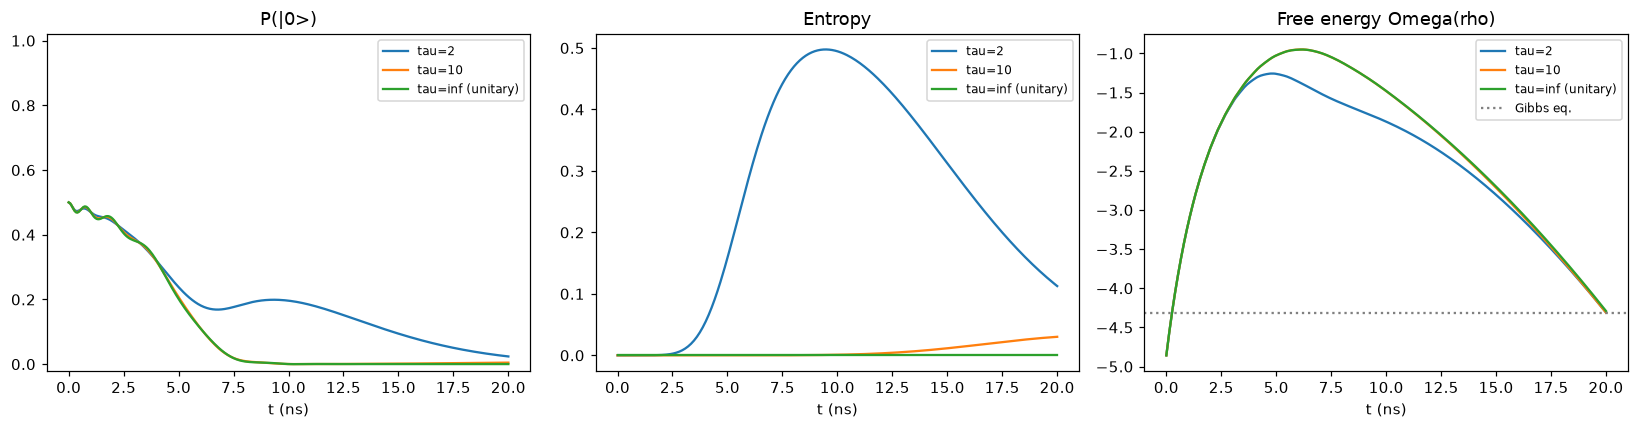

In [6]:
def run_1q_bath(H, t_anneal, tau, beta, n_points=300):
    rho0 = np.array([[0.5, 0.5], [0.5, 0.5]], dtype=complex)  # |+><+| (driver ground state)
    if np.isfinite(tau):
        diss = lambda t, rho, h: bath_dissipator(rho, h, beta, tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    p0 = np.array([np.real(r[0, 0]) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta) for t, r in zip(res.t, res.rho)])
    return res.t, p0, ent, omega

t_anneal_1q = 20.0
H_1q = hamiltonian_1qubit(schedule, h1=1.0, t_anneal=t_anneal_1q)
beta_bath = beta_from_kelvin(0.015)  # 15 mK
print(f"beta (15 mK) = {beta_bath:.4f} ns")

taus_1q = [2.0, 10.0, np.inf]
labels = {2.0: "tau=2", 10.0: "tau=10", np.inf: "tau=inf (unitary)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for tau in taus_1q:
    t, p0, ent, omega = run_1q_bath(H_1q, t_anneal_1q, tau, beta_bath)
    axes[0].plot(t, p0, label=labels[tau])
    axes[1].plot(t, ent, label=labels[tau])
    axes[2].plot(t, omega, label=labels[tau])
    print(f"{labels[tau]:>18}: final P(|0>)={p0[-1]:.4f}, final entropy={ent[-1]:.4f}, final Omega={omega[-1]:.4f}")
h1_final = H_1q(t_anneal_1q)
omega_eq_1q = free_energy(gibbs_state(h1_final, beta_bath), h1_final, beta_bath)
axes[2].axhline(omega_eq_1q, color="gray", linestyle=":", label="Gibbs eq.")
axes[0].set_title("P(|0>)"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
axes[2].set_title("Free energy Omega(rho)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("t (ns)")
fig.tight_layout(); plt.show()

## 3. $t_{\text{anneal}} \times \tau$ sweep (1 qubit, bath, real D-Wave schedule)

Since the bath's target is the Gibbs state rather than a fixed pure state,
dissipation doesn't only compete with reaching the answer the way a
fixed-energy dissipator would -- sweep across anneal time and relaxation
rate to see where it helps or hurts.

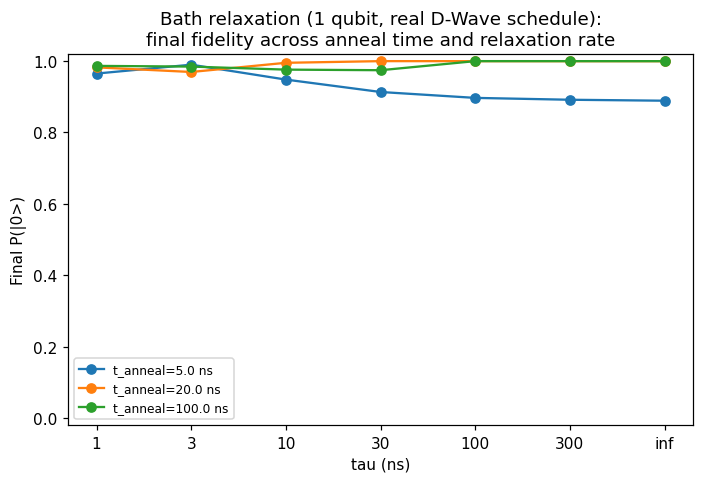

For a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than
the pure unitary limit -- unlike a fixed-energy dissipator, whose target is a
pure state and so can only compete with, never help, reaching one.


In [5]:
tau_sweep = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, np.inf]
labels_sweep = [f"{t:g}" if np.isfinite(t) else "inf" for t in tau_sweep]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for t_anneal in [5.0, 20.0, 100.0]:
    H_sweep = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal)
    finals = [run_1q_bath(H_sweep, t_anneal, tau, beta_bath, n_points=120)[1][-1] for tau in tau_sweep]
    ax.plot(labels_sweep, finals, marker="o", label=f"t_anneal={t_anneal} ns")
ax.set_xlabel("tau (ns)"); ax.set_ylabel("Final P(|0>)")
ax.set_title("Bath relaxation (1 qubit, real D-Wave schedule):\nfinal fidelity across anneal time and relaxation rate")
ax.legend(fontsize=8); ax.set_ylim(-0.02, 1.02)
fig.tight_layout(); plt.show()

print("For a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than")
print("the pure unitary limit -- unlike a fixed-energy dissipator, whose target is a")
print("pure state and so can only compete with, never help, reaching one.")

## 4. Extending to N qubits

`seaqt.operators` builds Pauli operators on any qubit of an $n$-qubit
register via Kronecker products, and assembles the (D-Wave-convention)
Ising Hamiltonian. `bath_dissipator` and `evolve` never assumed 2x2 --
they work unmodified for any Hilbert-space dimension.

In [7]:
H2 = ising_hamiltonian(2, h=[0.6, -0.4], J={(0, 1): 0.5}, A=1.0, B=0.7)
print("2-qubit Hamiltonian, shape", H2.shape, ", Hermitian:", np.allclose(H2, H2.conj().T))
print(H2.real)

rho2 = hermitize(np.eye(4, dtype=complex) / 4 + 0.05 * np.random.default_rng(0).normal(size=(4, 4)))
rho2 /= np.trace(rho2).real
D2 = bath_dissipator(rho2, H2, beta=1.0, tau=1.0)
print(f"\n2-qubit bath dissipator: Tr(D)={np.trace(D2):.2e}  (want 0)")

2-qubit Hamiltonian, shape (4, 4) , Hermitian: True
[[ 0.245 -0.5   -0.5    0.   ]
 [-0.5    0.175  0.    -0.5  ]
 [-0.5    0.    -0.525 -0.5  ]
 [ 0.    -0.5   -0.5    0.105]]

2-qubit bath dissipator: Tr(D)=-1.11e-16+0.00e+00j  (want 0)


## 5. Two qubits -- real D-Wave schedule + local SEAQT relaxation

The main result this repo is built around: two coupled qubits, the real
QPU annealing schedule, each qubit relaxing *locally* via
`local_seaqt_dissipator` (section 7 has the full derivation/validation).

The initial state is a slightly-thermalized driver state
(`gibbs_state(H(0), beta_init)`, `beta_init` large enough to be ~T=0 in
practice) rather than the exact pure ground state, and the linear bias
$h$ is genuinely asymmetric -- see section 6 for why. `tau_A=tau_B \ge 10`
ns is used here deliberately: section 7 shows positivity of $\rho$ can be
violated for smaller, more aggressive `tau` with this schedule.

Ground state: |10>, gap=7.7277
       tau_A=tau_B=5: final distribution P(|00>)=0.0049, P(|01>)=0.0392, P(|10>)=0.9241, P(|11>)=0.0319
      tau_A=tau_B=10: final distribution P(|00>)=0.0227, P(|01>)=0.0186, P(|10>)=0.9144, P(|11>)=0.0443
tau = inf (unitary only): final distribution P(|00>)=0.0008, P(|01>)=0.0046, P(|10>)=0.9880, P(|11>)=0.0066


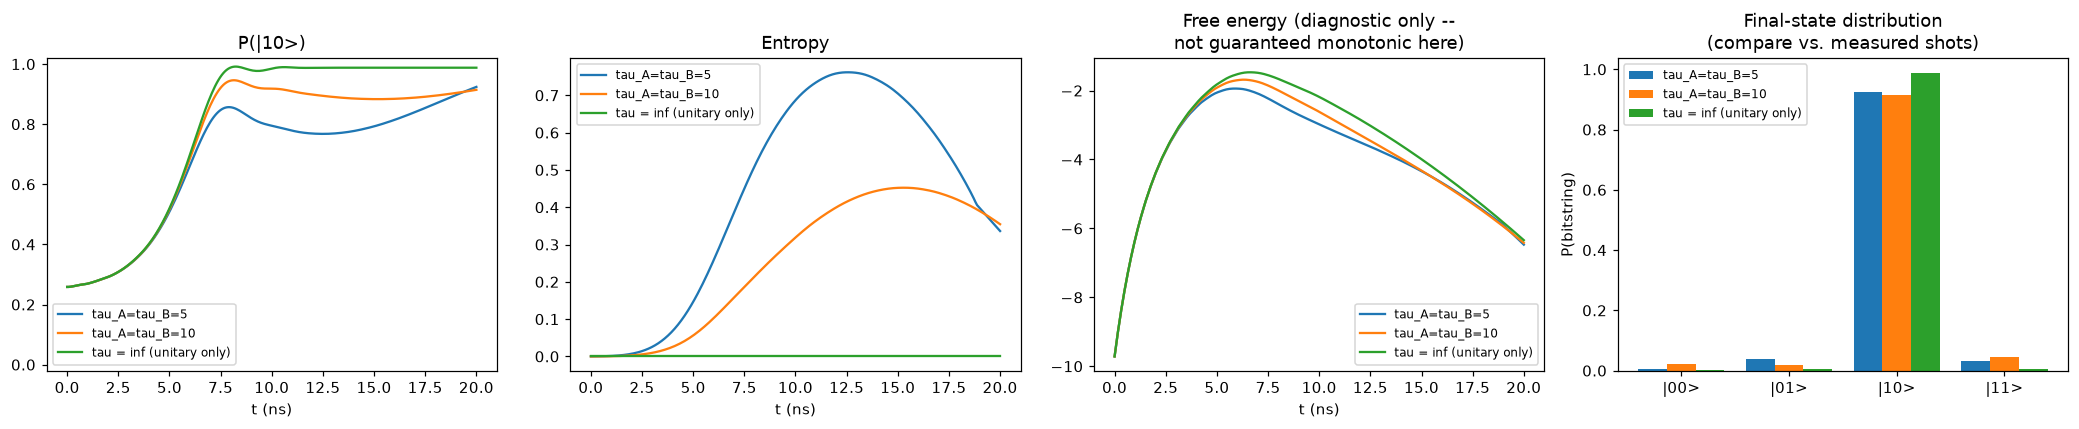

In [11]:
H_BIAS_2Q = [0.6, -0.4]
J12 = 0.5
BETA_INIT = 5.0

def run_2q_local_seaqt(H, t_anneal, tau, beta_r, n_points=250):
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r, tau_a=tau, tau_b=tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    ground_vec = v[:, 0]
    p_ground = np.array([np.real(ground_vec.conj() @ r @ ground_vec) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta_r) for t, r in zip(res.t, res.rho)])
    final_dist = population_distribution(res.rho[-1])
    return res.t, p_ground, ent, omega, final_dist

t_anneal_2q = 20.0
H_2q = hamiltonian_nqubit(schedule, h=H_BIAS_2Q, J={(0, 1): J12}, t_anneal=t_anneal_2q)
h2_final = H_2q(t_anneal_2q)
w2, v2 = np.linalg.eigh(h2_final)
labels_bits_2q = basis_labels(2)
ground_idx_2q = int(np.argmax(np.abs(v2[:, 0])))
print(f"Ground state: {labels_bits_2q[ground_idx_2q]}, gap={w2[1]-w2[0]:.4f}")

taus_2q = [5.0, 10.0, np.inf]
labels_2q = {5.0: "tau_A=tau_B=5", 10.0: "tau_A=tau_B=10", np.inf: "tau = inf (unitary only)"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
final_dists_2q = {}
for tau in taus_2q:
    t, p_ground, ent, omega, final_dist = run_2q_local_seaqt(H_2q, t_anneal_2q, tau, beta_bath)
    final_dists_2q[tau] = final_dist
    axes[0].plot(t, p_ground, label=labels_2q[tau])
    axes[1].plot(t, ent, label=labels_2q[tau])
    axes[2].plot(t, omega, label=labels_2q[tau])
    print(f"{labels_2q[tau]:>20}: final distribution " +
          ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))
axes[0].set_title(f"P({labels_bits_2q[ground_idx_2q]})"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
# Note: unlike bath_dissipator, local_seaqt_dissipator does NOT guarantee Omega
# decreases monotonically toward the global Gibbs state -- diagnostic only.
axes[2].set_title("Free energy (diagnostic only --\nnot guaranteed monotonic here)"); axes[2].legend(fontsize=8)
for a in axes[:3]: a.set_xlabel("t (ns)")

# Final-state distribution, grouped by tau -- the panel to overlay against a
# measured bitstring/shot histogram from real hardware (rho is represented in
# the computational/Z basis throughout, the same basis a QPU measures in).
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    axes[3].bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_2q[tau], width, label=labels_2q[tau])
axes[3].set_xticks(x); axes[3].set_xticklabels(labels_bits_2q)
axes[3].set_ylabel("P(bitstring)"); axes[3].set_title("Final-state distribution\n(compare vs. measured shots)")
axes[3].legend(fontsize=8)

fig.tight_layout(); plt.show()

## 6. A numerical note: degenerate eigenvalues and `bath_dissipator`

`bath_dissipator` computes $\ln\rho$ via `numpy.linalg.eigh` on $\rho$
itself, same as any density-matrix-eigendecomposition approach. An earlier
dissipator explored in this repo (steepest-entropy-ascent, fixed energy --
since removed to keep the repo focused on this bath model) turned out to
be numerically fragile here: for 2+ qubits, an **exactly pure** state has
a degenerate zero-eigenvalue eigenspace of dimension $d-1\ge 2$, and if
that eigenspace isn't aligned with $H$'s eigenbasis, `eigh` picks an
essentially arbitrary basis for it that changes *discontinuously* under
infinitesimal perturbations -- fatal for any ODE solver.

**`bath_dissipator` does not reproduce that failure mode** -- reproduced
directly below. The anticommutator construction with $\rho$ ($\{F,\rho\}$)
naturally suppresses sensitivity to the ambiguous eigenbasis in the
directions where $\rho$ has near-zero support, unlike a raw projection of
the entropy gradient.

In [8]:
H0_degenerate_driver = ising_hamiltonian(2, h=[0, 0], J=None, A=1.0, B=0.0)  # doubly-degenerate zero-energy eigenspace
w0, v0 = np.linalg.eigh(H0_degenerate_driver)
psi0 = v0[:, np.argmin(w0)]
rho0_pure = np.outer(psi0, psi0.conj())  # EXACT pure ground state

rng = np.random.default_rng(0)
print("Pure initial state, bath_dissipator (stable, not discontinuous):")
prev_D = None
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho0_pure + eps * perturb
    rho = rho / np.trace(rho).real
    D = bath_dissipator(rho, H0_degenerate_driver, beta=1.5, tau=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.4f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.4f}{change}")
    prev_D = D

Pure initial state, bath_dissipator (stable, not discontinuous):
  eps=0e+00: ||D||_max = 0.0000
  eps=1e-09: ||D||_max = 0.0000, ||delta D|| = 0.0000
  eps=1e-08: ||D||_max = 0.0000, ||delta D|| = 0.0000
  eps=1e-06: ||D||_max = 0.0000, ||delta D|| = 0.0000


A genuinely small minimum energy gap *anywhere along the schedule* (not
just at the initial state) is, as a matter of principle, more numerically
demanding to integrate accurately -- the "hard instance" phenomenon in
quantum annealing, not necessarily a bug. Let's test it directly on the
worst case available: the fully symmetric antiferromagnetic 2-qubit
problem (`h=[0,0]`), which has an *exactly* degenerate ground doublet at
the end of the anneal.

In [9]:
H_pathological = lambda t: ising_hamiltonian(
    2, h=[0, 0], J={(0, 1): 1.0}, A=(1 - np.clip(t / 20.0, 0, 1)) * 1.0, B=np.clip(t / 20.0, 0, 1)
)
diss_pathological = lambda t, rho, h: bath_dissipator(rho, h, beta=1.5, tau=2.0)
try:
    evolve(rho0_pure, hamiltonian=H_pathological, t_span=(0, 20.0), dissipator=diss_pathological, n_points=50)
    print("Integration succeeded.")
except RuntimeError as e:
    print(f"Integration failed (fast and with a clear error, not a silent hang): {e}")

Integration succeeded.


**Result: it succeeded.** Even the exactly-degenerate-schedule case
integrated fine with `bath_dissipator` -- a further point in favor of the
anticommutator construction's robustness compared to the old (removed)
fixed-energy dissipator, which hung on this exact setup for several
minutes before being tracked down. That doesn't mean small gaps are ever
*free* -- the underlying stiffness is real physics -- but `bath_dissipator`
tolerates it better in practice than the alternative did. This is also
why sections 4-5 above still default to a comfortable-gap problem: it's
the well-tested, reliably fast choice, not a requirement.

## 7. `local_seaqt_dissipator`: validation, and a real limitation (positivity)

Same rigor as section 1, now for the dissipator used in section 5. Three
checks, cross-checked once (not repeated here) to machine precision
($\sim10^{-16}$) against a literal port of the reference implementation
this was adapted from -- see `tests/test_local_seaqt.py`.

**(a) $D_J$ vanishes at its own local Gibbs fixed point.** Algebraic
identity (expand $\langle f\rangle_J$ and it cancels exactly) -- the same
kind of check as section 1's "vanishes at the Gibbs state".

In [10]:
rng = np.random.default_rng(3)
h_demo4 = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
m = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
rho_b_arbitrary = hermitize(m @ m.conj().T); rho_b_arbitrary /= np.trace(rho_b_arbitrary).real

h_a_actual = locally_perceived_operator(h_demo4, rho_b_arbitrary, target_qubit=0)
rho_a_eq = gibbs_state(h_a_actual, beta=1.7)
d_a = _subsystem_dissipator(rho_a_eq, h_a_actual, beta_r=1.7)
print(f"max|D_A| at its own local Gibbs state = {np.max(np.abs(d_a)):.3e}  (want ~0)")

max|D_A| at its own local Gibbs state = 1.541e-16  (want ~0)


**(b) Trace conservation and positivity, well-behaved `tau`.**

In [11]:
diss_ok = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=10.0, tau_b=10.0)
rho0_check = gibbs_state(H2, beta=5.0)
res_ok = evolve(rho0_check, hamiltonian=lambda t: H2, t_span=(0, 20), dissipator=diss_ok, n_points=150)
traces = [np.real(np.trace(r)) for r in res_ok.rho]
min_eig_ok = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_ok.rho)
print(f"trace range: [{min(traces):.8f}, {max(traces):.8f}]  (want ~1)")
print(f"min eigenvalue over trajectory: {min_eig_ok:.3e}  (want >= ~-1e-6)")

trace range: [1.00000000, 1.00000000]  (want ~1)
min eigenvalue over trajectory: 2.048e-05  (want >= ~-1e-6)


**(c) The limitation: positivity is NOT guaranteed for strong dissipation.**
Eq. 15 is derived in the paper as an *approximation* -- "[e]xpanding the
determinants and using the fact that the ratio of the inner products
$\epsilon=P_{SJ}/P_R$ is very small due to the large size of $R$" (the
effective reservoir is assumed to dominate over the local "system"). The
paper proves neither positivity preservation nor an explicit validity
range for $\tau_A,\tau_B,\beta_R$. Confirmed below on the real schedule
used in section 5: `tau=10` (section 5's default) stays essentially
positive; `tau=2` (aggressive) does not -- and this is *not* an
integration-tolerance artifact (unchanged at `rtol=1e-11` vs. the default
`1e-9`, tested separately).

In [12]:
rho0_2q = gibbs_state(H_2q(0.0), BETA_INIT)  # matches section 5's initial state exactly
for tau_test in [10.0, 2.0]:
    diss_test = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_bath, tau_a=tau_test, tau_b=tau_test)
    res_test = evolve(rho0_2q, hamiltonian=H_2q, t_span=(0, 20.0), dissipator=diss_test, n_points=150)
    min_eig_test = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_test.rho)
    print(f"tau={tau_test:>4}: min eigenvalue over trajectory = {min_eig_test:+.6f}")

print("\nThis is why section 5 defaults to tau_A=tau_B >= 10 ns for this schedule --")
print("the reliably well-behaved choice, not a proof that nothing smaller ever works.")

tau=10.0: min eigenvalue over trajectory = -0.000000


tau= 2.0: min eigenvalue over trajectory = -0.068397

This is why section 5 defaults to tau_A=tau_B >= 10 ns for this schedule --
the reliably well-behaved choice, not a proof that nothing smaller ever works.


## Next steps

- Push past 2 qubits -- `bath_dissipator`, `evolve`, and
  `seaqt.operators.ising_hamiltonian` already work for any finite
  Hilbert-space dimension $d=2^n$; going further is a runtime/tooling
  question, not a physics one. `local_seaqt_dissipator` is currently
  2-qubit-specific (eq. 7 generalizes to $M$ subsystems, but the
  implementation here only covers the bipartite $M=2$ case).
- Sweep $t_{\text{anneal}} \times \tau$ for the 2-qubit case the way
  section 3 already does for 1 qubit.
- Explore an intentionally (near-)degenerate multi-qubit ground-state
  manifold with a stiff-aware integration strategy (analytic Jacobian or a
  proper implicit solver) robust enough to handle the small-minimum-gap
  regime demonstrated in section 6.
- Investigate a positivity-preserving fix or bound for
  `local_seaqt_dissipator` (section 7) -- e.g. deriving beyond the paper's
  small-$\epsilon$ approximation, or a metric-respecting construction
  analogous to Beretta's full determinant formula.
- Explore state- or schedule-dependent $\tau(\rho, t)$ rather than a
  constant relaxation time.
- Compare against real D-Wave hardware results for a small problem
  instance, once available.